# 06 — `pandas` (Probabilitas Empiris dari Data)
**Mata Kuliah:** Probabilitas dan Statistika | **Nama / NIM:** ________

pandas dipakai untuk menghitung **probabilitas gabungan, marginal, bersyarat, dan distribusi empiris langsung dari data** (log server, log keamanan, hasil eksperimen). Data pada notebook ini adalah **log keamanan sintetis** yang dibangkitkan dengan parameter yang diketahui, sehingga hasil data dapat dibandingkan dengan nilai teori.

## 1. Eksplorasi Library
| Fungsi | Kegunaan |
|---|---|
| `Series.value_counts(normalize=True)` | PMF empiris |
| `pd.crosstab(a, b, normalize=..., margins=True)` | Tabel peluang gabungan / bersyarat / marginal |
| `groupby().agg()`, `pivot_table` | Peluang & statistik per kelompok |
| `describe`, `quantile`, `skew`, `kurt` | Ringkasan distribusi |
| `cov`, `corr` | Kovarians & korelasi |
| `pd.cut`, `pd.qcut` | Diskretisasi data kontinu |
| `sample(frac, replace=True)` | Resampling / bootstrap |
| `rolling`, `cumsum`, `expanding` | Konvergensi & deret waktu |

In [1]:
import numpy as np, pandas as pd, math
import matplotlib.pyplot as plt
from scipy import stats
rng=np.random.default_rng(2024)
N=20_000
protocol=rng.choice(["HTTP","SSH","FTP","DNS"],N,p=[.5,.2,.1,.2])
p_att={"HTTP":.02,"SSH":.10,"FTP":.15,"DNS":.01}
attack=rng.random(N)<pd.Series(protocol).map(p_att).values
df=pd.DataFrame({"protocol":protocol,"attack":attack,
    "hour":rng.integers(0,24,N),
    "resp_ms":rng.lognormal(4.5,.5,N)*np.where(attack,1.6,1.0),
    "bytes":rng.pareto(2.5,N)*500+200})
print(df.head()); print(df.shape); print(df.dtypes)
print(df.describe().round(2))

  protocol  attack  hour     resp_ms       bytes
0      SSH   False     7  118.903924  308.255320
1     HTTP   False     1   37.839776  360.907121
2     HTTP   False    18  100.769530  200.242897
3      FTP   False     5   90.135803  452.656814
4      DNS   False     9   67.103905  270.274135
(20000, 5)
protocol        str
attack         bool
hour          int64
resp_ms     float64
bytes       float64
dtype: object
           hour   resp_ms     bytes
count  20000.00  20000.00  20000.00
mean      11.43    104.72    533.37
std        6.92     56.19    641.06
min        0.00     12.47    200.01
25%        5.00     65.63    260.65
50%       11.00     91.96    360.10
75%       17.00    130.05    571.95
max       23.00    582.13  20941.66


**Rancangan data (nilai teori):** P(HTTP,SSH,FTP,DNS)=(0,5; 0,2; 0,1; 0,2); P(serangan|protokol)=(0,02; 0,10; 0,15; 0,01) → P(serangan) = 0,047.

## 2. Implementasi pada Permasalahan Probabilitas
### Soal 2.1 — Peluang marginal, gabungan, dan bersyarat (`crosstab`)
Hitung P(protokol), P(serangan), P(protokol ∩ serangan), dan P(serangan | protokol).

In [2]:
joint=pd.crosstab(df.protocol,df.attack,normalize='all',margins=True)
print("PELUANG GABUNGAN & MARGINAL\n",joint.round(4))
cond=pd.crosstab(df.protocol,df.attack,normalize='index')
print("\nP(serangan | protokol)\n",cond[True].round(4))
print("\nP(serangan) teori = 0.047 | data =",df.attack.mean().round(4))

PELUANG GABUNGAN & MARGINAL
 attack     False    True     All
protocol                        
DNS       0.1984  0.0016  0.2000
FTP       0.0834  0.0145  0.0980
HTTP      0.4872  0.0091  0.4964
SSH       0.1856  0.0202  0.2058
All       0.9546  0.0454  1.0000

P(serangan | protokol)
 protocol
DNS     0.0080
FTP     0.1480
HTTP    0.0183
SSH     0.0979
Name: True, dtype: float64

P(serangan) teori = 0.047 | data = 0.0454


**Interpretasi:** `normalize='all'` menghasilkan peluang gabungan (seluruh sel berjumlah 1), `normalize='index'` menghasilkan peluang bersyarat (tiap baris berjumlah 1). Estimasi data dekat dengan parameter sebenarnya (0,02; 0,10; 0,15; 0,01). SSH dan FTP yang hanya 30% trafik menyumbang mayoritas serangan.

### Soal 2.2 — Uji independensi & Teorema Bayes dari data
(a) Apakah `protocol` independen dari `attack`? Bandingkan P(A∩B) dengan P(A)P(B). (b) Hitung P(SSH | serangan) dengan Bayes dan bandingkan dengan perhitungan langsung.
**Manual (teori):** P(SSH|serangan)=0,2·0,10/0,047≈0,4255.

In [3]:
pA=df.attack.mean(); pS=(df.protocol=="SSH").mean(); pAS=((df.protocol=="SSH")&df.attack).mean()
print("P(A)P(SSH) =",round(pA*pS,5)," | P(A∩SSH) =",round(pAS,5),"-> tidak sama => TIDAK independen")
chi2,p,dof,_=stats.chi2_contingency(pd.crosstab(df.protocol,df.attack))
print(f"uji chi2: chi2={chi2:.1f} p={p:.2e}")
# Bayes
p_s_given_a = ((df.protocol=="SSH")&df.attack).sum()/df.attack.sum()      # langsung
p_a_given_s = df[df.protocol=="SSH"].attack.mean()
bayes = p_a_given_s*pS/pA
print("P(SSH|serangan) langsung =",round(p_s_given_a,4)," | via Bayes =",round(bayes,4)," | teori 0.4255")
print("Distribusi protokol DI ANTARA serangan:\n",df[df.attack].protocol.value_counts(normalize=True).round(3))

P(A)P(SSH) = 0.00933  | P(A∩SSH) = 0.02015 -> tidak sama => TIDAK independen
uji chi2: chi2=1036.1 p=2.60e-224
P(SSH|serangan) langsung = 0.4443  | via Bayes = 0.4443  | teori 0.4255
Distribusi protokol DI ANTARA serangan:
 protocol
SSH     0.444
FTP     0.320
HTTP    0.201
DNS     0.035
Name: proportion, dtype: float64


**Interpretasi:** Data menolak independensi (p ≈ 0): mengetahui protokol mengubah peluang serangan. Rumus Bayes memberi angka identik dengan perhitungan langsung, membuktikan keduanya konsisten. Sekitar 44% serangan berasal dari SSH meski hanya ±20% trafik (angka teori 42,6% berbeda tipis karena fluktuasi sampel: proporsi serangan data 4,54% vs 4,7%).

### Soal 2.3 — Hukum probabilitas total & prioritas investigasi
Jika sebuah alert muncul untuk protokol acak, berapa peluang total? Protokol mana yang paling layak diperiksa lebih dulu (P(protokol | serangan))? Hitung P(serangan) = Σ P(serangan|protokol)P(protokol).

P(serangan) lewat hukum total = 0.0454  | langsung = 0.0454

Posterior P(protokol | serangan):
 protocol
SSH     0.4443
FTP     0.3197
HTTP    0.2007
DNS     0.0353
dtype: float64


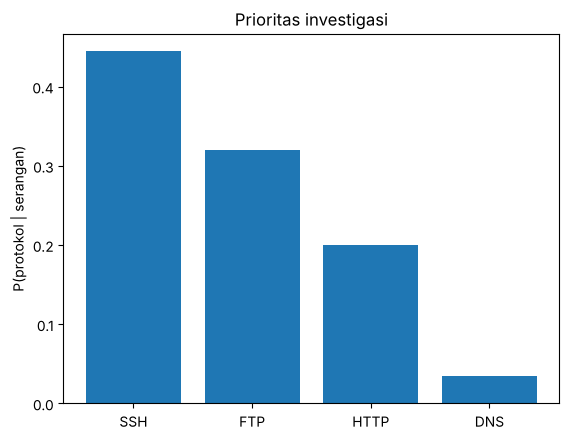

In [4]:
prior=df.protocol.value_counts(normalize=True)
lik=df.groupby("protocol").attack.mean()
total=(prior*lik).sum()
post=(prior*lik/total).sort_values(ascending=False)
print("P(serangan) lewat hukum total =",round(total,4)," | langsung =",round(df.attack.mean(),4))
print("\nPosterior P(protokol | serangan):\n",post.round(4))
plt.bar(post.index,post.values); plt.ylabel("P(protokol | serangan)"); plt.title("Prioritas investigasi"); plt.show()

**Interpretasi:** Hukum probabilitas total memberikan 0,047 yang sama dengan frekuensi langsung. Urutan prioritas ditentukan oleh *prior × likelihood*, bukan likelihood saja: SSH di atas FTP walau FTP lebih berbahaya per koneksi, karena volume SSH dua kali lipat.

### Soal 2.4 — Paradoks Simpson (peluang bersyarat bisa menyesatkan)
Dua patch keamanan diuji pada sistem **kecil** dan **besar**. Patch B tampak lebih baik secara agregat, tetapi A lebih baik di setiap kelompok.

In [5]:
t=pd.DataFrame({"patch":["A","A","B","B"],"sistem":["kecil","besar","kecil","besar"],
                "sukses":[81,192,234,55],"total":[87,263,270,80]})
t["rate"]=t.sukses/t.total
print(t.round(3))
agg=t.groupby("patch")[["sukses","total"]].sum(); agg["rate"]=agg.sukses/agg.total
print("\nAGREGAT:\n",agg.round(3))
print("\nProporsi kelompok: A diuji pada sistem besar =",round(263/350,3),"| B =",round(80/350,3))

  patch sistem  sukses  total   rate
0     A  kecil      81     87  0.931
1     A  besar     192    263  0.730
2     B  kecil     234    270  0.867
3     B  besar      55     80  0.688

AGREGAT:
        sukses  total   rate
patch                      
A         273    350  0.780
B         289    350  0.826

Proporsi kelompok: A diuji pada sistem besar = 0.751 | B = 0.229


**Interpretasi:** Patch A: 93,1% (kecil), 73,0% (besar) → lebih baik di **kedua** kelompok; namun agregat A=78,0% < B=82,6%. Penyebab: A lebih banyak diuji pada kasus sulit (sistem besar, 75% vs 23%). Variabel pengganggu (*confounder*) harus dikendalikan sebelum menyimpulkan.

## 3. Implementasi pada Distribusi Probabilitas
### Soal 3.1 — PMF empiris Poisson: request per menit
Simulasikan 1 hari (1440 menit) request dengan λ=5/menit. Bandingkan PMF empiris dengan Poisson(5), dan E, Var.

req          0       1       2       3       4       5       6       7   \
empiris  0.0035  0.0229  0.0875  0.1326  0.1958  0.1743  0.1444  0.1076   
teori    0.0067  0.0337  0.0842  0.1404  0.1755  0.1755  0.1462  0.1044   

req          8       9       10      11      12      15  
empiris  0.0715  0.0306  0.0132  0.0097  0.0049  0.0014  
teori    0.0653  0.0363  0.0181  0.0082  0.0034  0.0002  
mean = 5.036  var = 4.734 (teori 5 dan 5)  | P(>=10) emp = 0.0292  teori = 0.0318


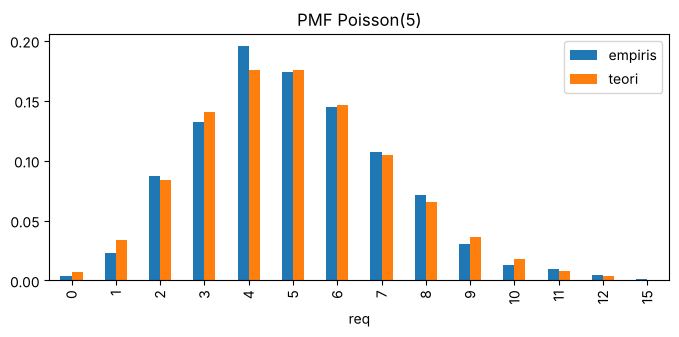

In [6]:
perm=pd.Series(rng.poisson(5,1440),name="req")
emp=perm.value_counts(normalize=True).sort_index()
th=pd.Series(stats.poisson(5).pmf(emp.index),index=emp.index)
cmp=pd.DataFrame({"empiris":emp,"teori":th}).round(4); print(cmp.T)
print("mean =",perm.mean().round(3)," var =",perm.var().round(3),"(teori 5 dan 5)  | P(>=10) emp =",(perm>=10).mean().round(4)," teori =",stats.poisson(5).sf(9).round(4))
cmp.plot(kind='bar',figsize=(8,3.2)); plt.title("PMF Poisson(5)"); plt.show()

**Interpretasi:** Rata-rata (5,04) ≈ varians (4,73) ≈ 5 (ciri Poisson). Hanya 1.440 sampel sehingga PMF empiris masih sedikit bergelombang; deviasi seperti ini normal dan mengecil bila data lebih banyak.

### Soal 3.2 — Distribusi miring (log-normal): waktu respons
Analisis `resp_ms`: skewness, kurtosis, persentil, perbandingan normal vs serangan, dan kecocokan log-normal setelah transformasi log.

mean=104.7 median=92.0 skew=1.70 kurt=5.14
persentil: {0.5: 92.0, 0.9: 177.8, 0.95: 210.3, 0.99: 293.6}
log(resp): mean=4.504 sd=0.496 skew=-0.005 (normal ~0)
         mean  median   std
attack                     
False   102.2    90.2  53.6
True    158.0   142.8  78.4


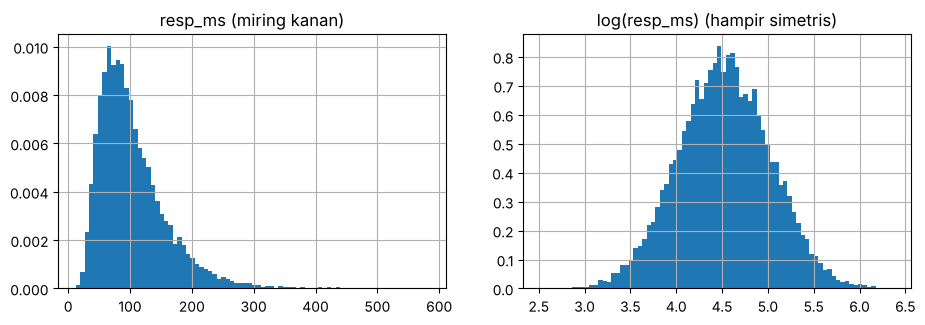

In [7]:
r=df.resp_ms
print("mean=%.1f median=%.1f skew=%.2f kurt=%.2f"%(r.mean(),r.median(),r.skew(),r.kurt()))
print("persentil:",r.quantile([.5,.9,.95,.99]).round(1).to_dict())
print("log(resp): mean=%.3f sd=%.3f skew=%.3f (normal ~0)"%(np.log(r[~df.attack]).mean(),np.log(r[~df.attack]).std(),np.log(r[~df.attack]).skew()))
print(df.groupby("attack").resp_ms.agg(["mean","median","std"]).round(1))
fig,ax=plt.subplots(1,2,figsize=(11,3.3))
df.resp_ms.hist(bins=80,ax=ax[0],density=True); ax[0].set_title("resp_ms (miring kanan)")
np.log(df.resp_ms).hist(bins=80,ax=ax[1],density=True); ax[1].set_title("log(resp_ms) (hampir simetris)"); plt.show()

**Interpretasi:** Mean (>median) dan skewness positif menunjukkan ekor kanan panjang. Setelah di-log, data hampir simetris → model **log-normal** cocok (log-mean ≈4,5; sd ≈0,5 sesuai parameter). Respons saat serangan ±1,6× lebih lambat, sehingga `resp_ms` dapat dipakai sebagai fitur deteksi.

### Soal 3.3 — Binomial dari agregasi: serangan per jam
Per jam ada ±833 koneksi. Jumlah serangan per jam ≈ Binomial(n,0,047). Cek rata-rata, varians dan pendekatan Normal.

n rata-rata/jam=833  mean serangan=37.8 (np=37.8)  var=26.9 (npq=36.1)
z-score maks per jam: 2.03  (jam ke- 0 )


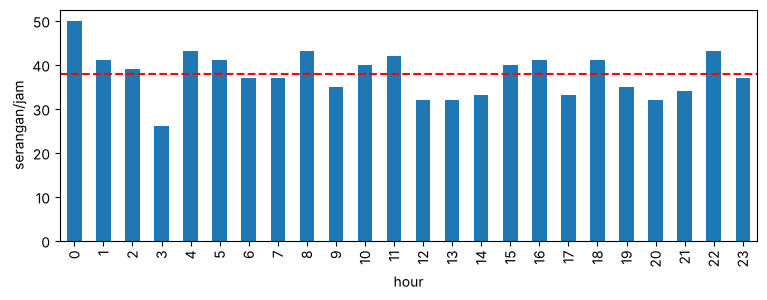

In [8]:
h=df.groupby("hour").attack.agg(["sum","count"])
n=h["count"].mean(); p=df.attack.mean()
print("n rata-rata/jam=%.0f  mean serangan=%.1f (np=%.1f)  var=%.1f (npq=%.1f)"%(n,h["sum"].mean(),n*p,h["sum"].var(),n*p*(1-p)))
z=(h["sum"]-n*p)/math.sqrt(n*p*(1-p)); print("z-score maks per jam:",z.abs().max().round(2)," (jam ke-",z.abs().idxmax(),")")
h["sum"].plot(kind='bar',figsize=(9,3)); plt.axhline(n*p,c='r',ls='--'); plt.ylabel("serangan/jam"); plt.show()

**Interpretasi:** Jumlah serangan tiap jam berfluktuasi di sekitar np≈38 dengan simpangan teori ≈6,0; nilai |z| terbesar hanya ≈2,0 sehingga semua jam berada dalam |z|<3 → tidak ada jam yang anomali (sesuai karena data dibangkitkan homogen). Pada log nyata, |z|>3 akan menandai jam mencurigakan.

### Soal 3.4 — Distribusi *heavy-tail* (Pareto) dan ECDF: ukuran transfer
Gunakan `bytes` (Pareto). Bangun ECDF, hitung P(bytes>2000), dan ukur kontribusi 1% transfer terbesar terhadap total.

P(bytes>2000) emp = 0.0223  teori = 0.022 (Lomax: (1+x/500)^-2.5)
1% transfer terbesar = 9.2% dari total byte | mean=533 median=360


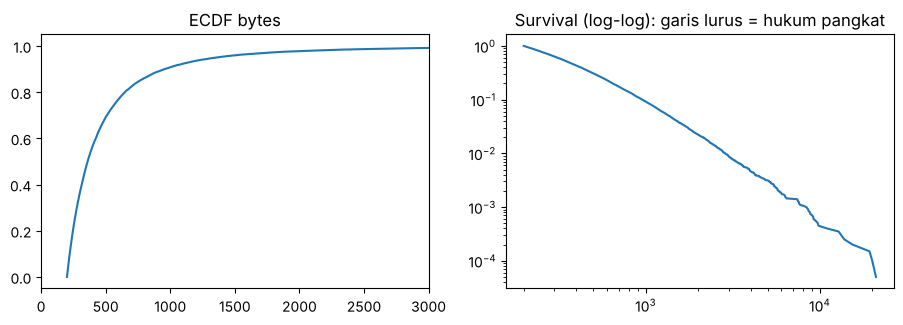

In [9]:
b=df.bytes.sort_values().reset_index(drop=True)
ecdf=(np.arange(1,len(b)+1)/len(b))
print("P(bytes>2000) emp =",(df.bytes>2000).mean().round(4)," teori =",round((1+(2000-200)/500)**-2.5,4),"(Lomax: (1+x/500)^-2.5)")
top=df.bytes.nlargest(int(.01*N)).sum()/df.bytes.sum()
print("1%% transfer terbesar = %.1f%% dari total byte | mean=%.0f median=%.0f"%(top*100,df.bytes.mean(),df.bytes.median()))
fig,ax=plt.subplots(1,2,figsize=(11,3.3))
ax[0].plot(b,ecdf); ax[0].set_xlim(0,3000); ax[0].set_title("ECDF bytes")
ax[1].loglog(b,1-ecdf+1/N); ax[1].set_title("Survival (log-log): garis lurus = hukum pangkat"); plt.show()

**Interpretasi:** Ekor berat: 1% transfer terbesar menyumbang ±9% total byte, dan mean (533) jauh di atas median (360). Peluang empiris P(bytes>2000)=0,022 cocok dengan rumus Lomax teori (≈0,022). Pada plot log–log kurva survival hampir linier (ciri hukum pangkat/Pareto).

### Soal 3.5 — Kovarians & korelasi (distribusi gabungan)
Hitung matriks korelasi antar `resp_ms`, `bytes`, `attack`, `hour` dan visualisasikan.

         resp_ms  bytes  attack   hour
resp_ms    1.000  0.000   0.207  0.006
bytes      0.000  1.000   0.003 -0.007
attack     0.207  0.003   1.000 -0.005
hour       0.006 -0.007  -0.005  1.000

Cov(resp_ms, attack) = 2.42


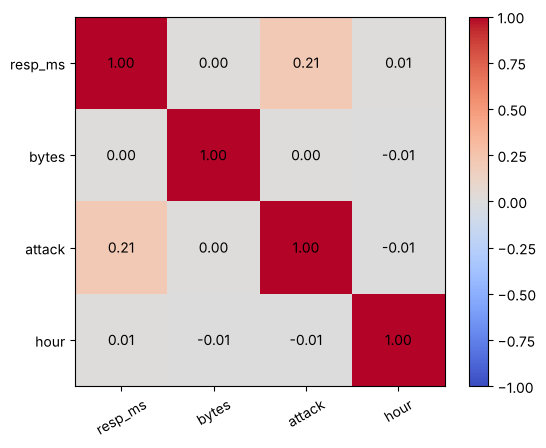

In [10]:
M=df[["resp_ms","bytes","attack","hour"]].astype(float)
corr=M.corr(); print(corr.round(3)); print("\nCov(resp_ms, attack) =",M.cov().loc["resp_ms","attack"].round(2))
plt.imshow(corr,cmap="coolwarm",vmin=-1,vmax=1); plt.xticks(range(4),corr.columns,rotation=30); plt.yticks(range(4),corr.columns); plt.colorbar()
for i in range(4):
    for j in range(4): plt.text(j,i,f"{corr.iloc[i,j]:.2f}",ha="center",va="center")
plt.show()

**Interpretasi:** Hanya `resp_ms`–`attack` yang berkorelasi nyata (positif), karena dibangun begitu; pasangan lain ≈0 (independen secara desain). Korelasi ≈0 tidak selalu berarti independen (hanya hubungan linear), tetapi di sini selaras dengan rancangan data.

## 4. Pengembangan Contoh Permasalahan
### Soal 4.1 — Bootstrap CI untuk tingkat serangan per protokol
Berapa ketidakpastian estimasi P(serangan|SSH)? Gunakan 2.000 resampel dan bandingkan dengan CI Normal (Wald).

In [11]:
ssh=df[df.protocol=="SSH"].attack.astype(int).reset_index(drop=True)
bs=pd.Series([ssh.sample(frac=1,replace=True,random_state=i).mean() for i in range(2000)])
lo,hi=bs.quantile([.025,.975]); ph=ssh.mean(); se=math.sqrt(ph*(1-ph)/len(ssh))
print("n SSH =",len(ssh)," p_hat =",round(ph,4))
print("CI bootstrap 95%% : [%.4f, %.4f]"%(lo,hi))
print("CI Wald 95%%      : [%.4f, %.4f]  (teori p=0.10)"%(ph-1.96*se,ph+1.96*se))

n SSH = 4115  p_hat = 0.0979
CI bootstrap 95% : [0.0894, 0.1072]
CI Wald 95%      : [0.0889, 0.1070]  (teori p=0.10)


**Interpretasi:** Kedua metode hampir identik (selang ≈ ±0,9 poin persen) dan memuat nilai sebenarnya 0,10. Ukuran sampel menentukan lebar CI; protokol FTP (n kecil) memberi CI lebih lebar.

### Soal 4.2 — Konvergensi Hukum Bilangan Besar dari data (`expanding().mean()`)

n=    10: rata-rata serangan = 0.0000
n=   100: rata-rata serangan = 0.0300
n=  1000: rata-rata serangan = 0.0450
n= 10000: rata-rata serangan = 0.0455
n= 20000: rata-rata serangan = 0.0454


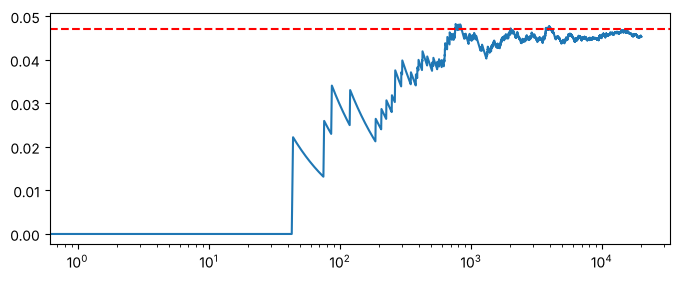

In [12]:
run=df.attack.astype(int).expanding().mean()
for n_ in (10,100,1000,10000,20000): print(f"n={n_:>6}: rata-rata serangan = {run.iloc[n_-1]:.4f}")
run.plot(logx=True,figsize=(8,3)); plt.axhline(.047,c='r',ls='--'); plt.show()

**Interpretasi:** Estimasi peluang serangan menuju 0,047 seiring bertambahnya data; pada n kecil bisa meleset jauh. Galat baku ≈ √(p(1−p)/n): ±0,021 untuk n=100 vs ±0,0015 untuk n=20.000.

### Soal 4.3 — Uji A/B pada data: konversi dua varian
Varian A: 120/1000 konversi; Varian B: 150/1000. Gunakan tabel kontingensi dan peluang bersyarat (`crosstab`) serta uji proporsi.

In [13]:
ab=pd.DataFrame({"varian":["A"]*1000+["B"]*1000,"konversi":[1]*120+[0]*880+[1]*150+[0]*850})
print(pd.crosstab(ab.varian,ab.konversi,margins=True))
print(pd.crosstab(ab.varian,ab.konversi,normalize='index').round(3))
ct=pd.crosstab(ab.varian,ab.konversi)
print("chi2 p =",round(stats.chi2_contingency(ct,correction=False)[1],4)," | Fisher exact p =",round(stats.fisher_exact(ct)[1],4))
rr=(150/1000)/(120/1000); print("Rasio peluang (relative risk) =",round(rr,3))

konversi     0    1   All
varian                   
A          880  120  1000
B          850  150  1000
All       1730  270  2000
konversi     0     1
varian              
A         0.88  0.12
B         0.85  0.15
chi2 p = 0.0496  | Fisher exact p = 0.0576
Rasio peluang (relative risk) = 1.25


**Interpretasi:** B 15% vs A 12% (naik 25% relatif). Uji χ² memberi p≈0,0496 (tepat di batas α=0,05) sedangkan uji eksak Fisher memberi p≈0,058 (tidak signifikan). Dua uji yang sah bisa menghasilkan keputusan berbeda saat p dekat batas — kesimpulan yang jujur: bukti B lebih baik **lemah/borderline**, perlu sampel lebih besar atau pendekatan Bayes (lihat notebook SciPy).

## Kesimpulan
1. pandas mengubah data mentah menjadi **PMF empiris, peluang gabungan/marginal/bersyarat** hanya dengan `value_counts` dan `crosstab`.
2. Teorema Bayes, hukum probabilitas total, dan uji independensi dapat diverifikasi langsung dari data.
3. Paradoks Simpson mengingatkan bahwa peluang agregat dapat menyesatkan tanpa mengontrol variabel pengganggu.
4. pandas bukan mesin distribusi: untuk CDF/kuantil teori dan uji statistik pasangkan dengan SciPy.